# Projet : Analyse de sentiments (polarité et émotions) — PHASE 1
**Contenu :** Data collection → Data understanding → Data preparation (nettoyage, transformation, intégration, enrichissement).

**Entrée :** `data/raw/final_dataset.csv` (jamais modifié).
**Sorties :** `data/processed/*`, `plots/*.png`, `data/processed/resultats_phase1.json`.

Équipe : Ala Eddine Saihi, Jawaher Fakraoui — Encadrante : Mariem Ghzara — ING Info 2 — 2026-2027

In [1]:
import os, re, json
from collections import Counter
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import scipy.sparse as sp
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

try:                              # exécution comme script : code/phase1_pipeline.py
    BASE = os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
except NameError:                 # exécution dans un notebook placé dans code/
    BASE = os.path.abspath("..")
RAW = os.path.join(BASE, "data", "raw", "final_dataset.csv")
PROC = os.path.join(BASE, "data", "processed")
PLOTS = os.path.join(BASE, "plots")
os.makedirs(PROC, exist_ok=True); os.makedirs(PLOTS, exist_ok=True)

SEED = 42
R = {}                            # tous les résultats chiffrés, repris dans le rapport
def save_fig(name):
    plt.tight_layout(); plt.savefig(os.path.join(PLOTS, name), dpi=130); plt.show()

## 1. Data collection : chargement des données brutes

In [2]:
raw = pd.read_csv(RAW)
R["n_rows"], R["n_cols"] = raw.shape
R["dtypes"] = {c: str(t) for c, t in raw.dtypes.items()}
R["file_size_mb"] = round(os.path.getsize(RAW) / 1e6, 1)
print(raw.shape); print(raw.head())

(106355, 2)
                                                text     emotion
0  i feel rather funny ending with so many dupes ...         fun
1                     i feel surprised by the result    surprise
2                    i am officially feeling festive     neutral
3  i suddenly found myself standing before this w...    surprise
4  i look at the meager pile of food i purchased ...  enthusiasm


## 2. Data understanding : description et qualité

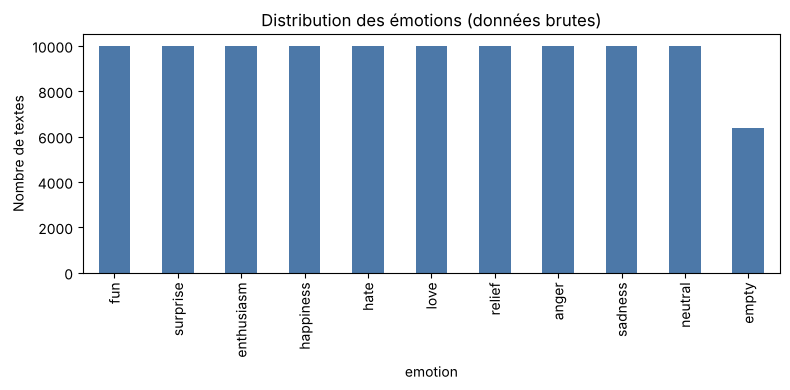

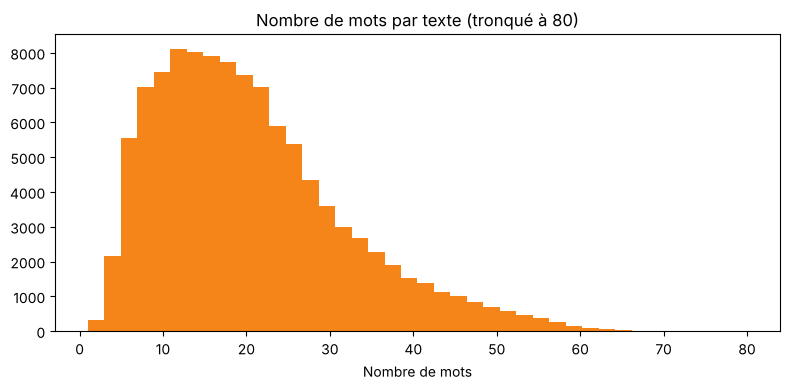

In [3]:
R["missing"] = int(raw.isna().sum().sum())
R["dup_rows"] = int(raw.duplicated().sum())
R["dup_text"] = int(raw.text.duplicated().sum())
raw["n_words"] = raw.text.str.split().str.len()
R["len_stats"] = {k: float(v) for k, v in raw.n_words.describe().items()}
R["short"] = int((raw.n_words <= 3).sum()); R["long"] = int((raw.n_words > 60).sum())
R["url_at"] = int(raw.text.str.contains(r"http|www\.|@").sum())
R["digits"] = int(raw.text.str.contains(r"\d").sum())
R["non_ascii"] = int(raw.text.str.contains(r"[^\x00-\x7f]").sum())
R["mojibake"] = int(raw.text.str.contains("ï¿½").sum())      # caractères corrompus (erreur d'encodage)
R["html_entities"] = int(raw.text.str.contains(r"&(?:quot|amp|lt|gt);").sum())
R["upper"] = int(raw.text.str.contains(r"[A-Z]").sum())
R["punct"] = int(raw.text.str.contains(r"[.,!?;:]").sum())
R["classes_raw"] = raw.emotion.value_counts().to_dict()
conf_raw = raw.groupby("text").emotion.nunique()
R["conflicts_raw"] = int((conf_raw > 1).sum())

# Graphique 1 : distribution des émotions (brut)
plt.figure(figsize=(8, 4))
raw.emotion.value_counts().plot.bar(color="#4C78A8")
plt.title("Distribution des émotions (données brutes)"); plt.ylabel("Nombre de textes")
save_fig("01_distribution_emotions_brut.png")

# Graphique 2 : longueur des textes
plt.figure(figsize=(8, 4))
plt.hist(raw.n_words.clip(upper=80), bins=40, color="#F58518")
plt.title("Nombre de mots par texte (tronqué à 80)"); plt.xlabel("Nombre de mots")
save_fig("02_longueur_textes.png")

### Analyse du style : les textes viennent-ils de sources différentes ?

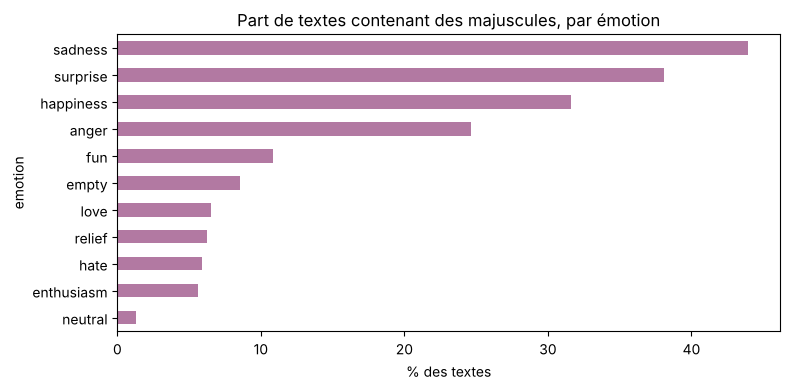

In [4]:
raw["has_upper"] = raw.text.str.contains(r"[A-Z]")
raw["has_punct"] = raw.text.str.contains(r"[.,!?;:]")
style = raw.groupby("emotion").agg(pct_majuscules=("has_upper", "mean"), pct_ponctuation=("has_punct", "mean"),
                                   mots_moyens=("n_words", "mean"), nb_textes=("text", "count")).round(4)
R["style"] = style.reset_index().to_dict(orient="records")

plt.figure(figsize=(8, 4))
(style.pct_majuscules * 100).sort_values().plot.barh(color="#B279A2")
plt.title("Part de textes contenant des majuscules, par émotion"); plt.xlabel("% des textes")
save_fig("03_style_par_emotion.png")

# Le style seul (majuscules, ponctuation, longueur) permet-il de deviner l'émotion ?
Xs = raw[["has_upper", "has_punct", "n_words"]].astype(int)
Xa, Xb, ya, yb = train_test_split(Xs, raw.emotion, test_size=0.2, stratify=raw.emotion, random_state=SEED)
tree = DecisionTreeClassifier(max_depth=5).fit(Xa, ya)
R["style_acc"] = round(accuracy_score(yb, tree.predict(Xb)), 3); R["chance"] = round(1 / raw.emotion.nunique(), 3)

### Qualité des étiquettes : des mots-clés cachés dans d'autres mots ?
Hypothèse : une partie des étiquettes viendrait d'une recherche automatique de mots-clés (par ex. « rage » dans « average »).

In [5]:
def clean(t):
    t = t.lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)      # URL
    t = re.sub(r"@\w+", " ", t)                  # mentions
    t = re.sub(r"\d+", " ", t)                   # chiffres
    t = re.sub(r"[^a-z' ]", " ", t)              # ponctuation, symboles, non-ASCII
    return re.sub(r"\s+", " ", t).strip()

## 3. Data preparation : nettoyage (étape par étape, avec le nombre de lignes à chaque étape)

[('Dataset brut', 106355), ('Doublons exacts supprimés', 80826), ('Textes à étiquettes contradictoires supprimés', 80758), ('Filtre de longueur (4 à 60 mots)', 79781), ("Texte nettoyé d'au moins 3 mots", 79770), ('Doublons et contradictions après nettoyage', 79565)]


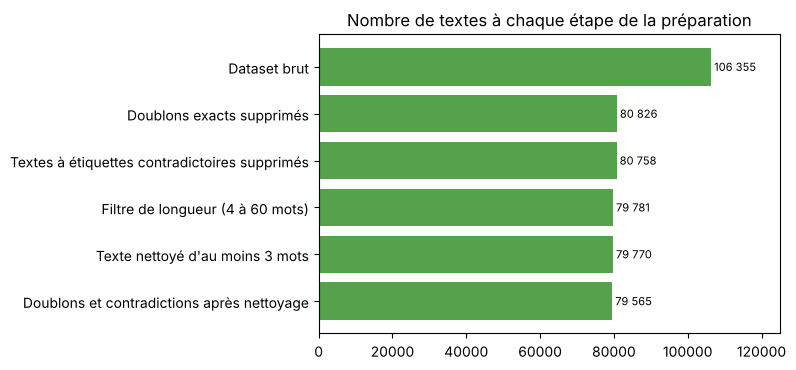

In [6]:
steps = [("Dataset brut", len(raw))]
d = raw.drop_duplicates(subset=["text", "emotion"]).copy()
steps.append(("Doublons exacts supprimés", len(d)))
d = d[~d.text.isin(conf_raw[conf_raw > 1].index)]
steps.append(("Textes à étiquettes contradictoires supprimés", len(d)))
d = d[(d.n_words >= 4) & (d.n_words <= 60)]
steps.append(("Filtre de longueur (4 à 60 mots)", len(d)))
d["clean"] = d.text.map(clean)
d["n_clean"] = d.clean.str.split().str.len()
d = d[d.n_clean >= 3]
steps.append(("Texte nettoyé d'au moins 3 mots", len(d)))
R["dup_after_clean"] = int(d.clean.duplicated().sum())
conf2 = d.groupby("clean").emotion.nunique()
R["conflicts_after_clean"] = int((conf2 > 1).sum())
d = d[~d.clean.isin(conf2[conf2 > 1].index)].drop_duplicates(subset="clean").reset_index(drop=True)
steps.append(("Doublons et contradictions après nettoyage", len(d)))
R["steps"] = steps; R["n_after"] = len(d); R["removed"] = len(raw) - len(d)
R["classes_after"] = d.emotion.value_counts().to_dict()
R["html_residue"] = int(d.clean.str.contains(r"\bhref\b|\bhttp\b").sum())   # résidus HTML restant après nettoyage
R["mojibake_kept"] = int(d.text.str.contains("ï¿½").sum())
print(steps)

# Graphique : entonnoir de nettoyage
plt.figure(figsize=(8, 3.8))
plt.barh([s[0] for s in steps][::-1], [s[1] for s in steps][::-1], color="#54A24B")
for i, v in enumerate([s[1] for s in steps][::-1]): plt.text(v + 800, i, f"{v:,}".replace(",", " "), va="center", fontsize=8)
plt.xlim(0, 125000); plt.title("Nombre de textes à chaque étape de la préparation")
save_fig("04_entonnoir_nettoyage.png")

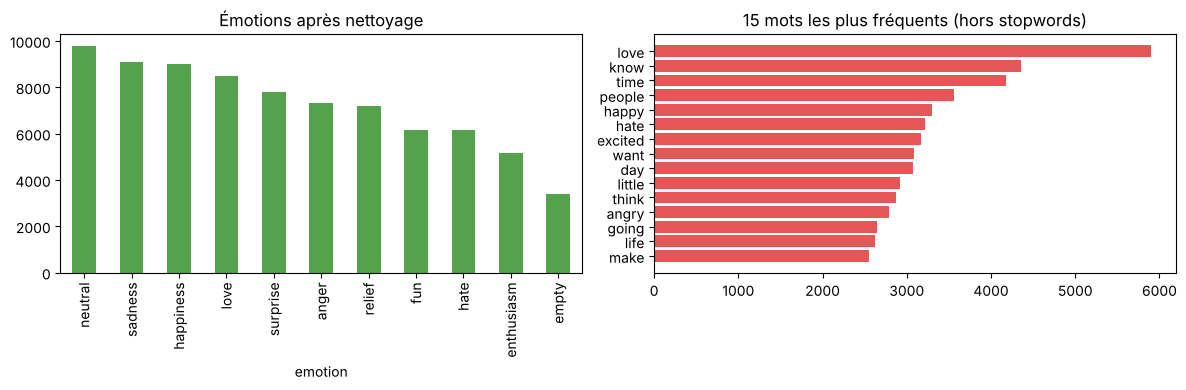

In [7]:
STOP_PLOT = set(ENGLISH_STOP_WORDS) | {"feel", "feeling", "felt", "like", "im", "ive", "just", "really", "ll", "don", "didn"}
top = Counter(w for t in d.clean for w in t.split() if w not in STOP_PLOT and len(w) > 2).most_common(15)
R["top_words"] = top
R["top_words_emotion"] = {e: [w for w, _ in Counter(w for t in g.clean for w in t.split() if w not in STOP_PLOT and len(w) > 2).most_common(6)] for e, g in d.groupby("emotion")}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
d.emotion.value_counts().plot.bar(ax=ax[0], color="#54A24B"); ax[0].set_title("Émotions après nettoyage")
ax[1].barh([w for w, _ in top][::-1], [c for _, c in top][::-1], color="#E45756"); ax[1].set_title("15 mots les plus fréquents (hors stopwords)")
save_fig("05_apres_nettoyage.png")

### Vérification de la qualité des étiquettes (mots-clés cachés)

In [8]:
checks = {"average": "anger", "avoid": "empty", "function": "fun", "whatever": "hate",
          "unloved": "love", "discomfort": "relief", "unhappy": "happiness"}
share = d.emotion.value_counts(normalize=True)
R["label_checks"] = []
for w, e in checks.items():
    m = d.clean.str.contains(r"\b" + w + r"\b")
    R["label_checks"].append({"mot": w, "emotion": e, "n": int(m.sum()),
                              "part_emotion": round(float((d[m].emotion == e).mean()), 4), "part_classe": round(float(share[e]), 4)})

## 4. Data transformation : découpage, vectorisation TF-IDF, réduction de dimension

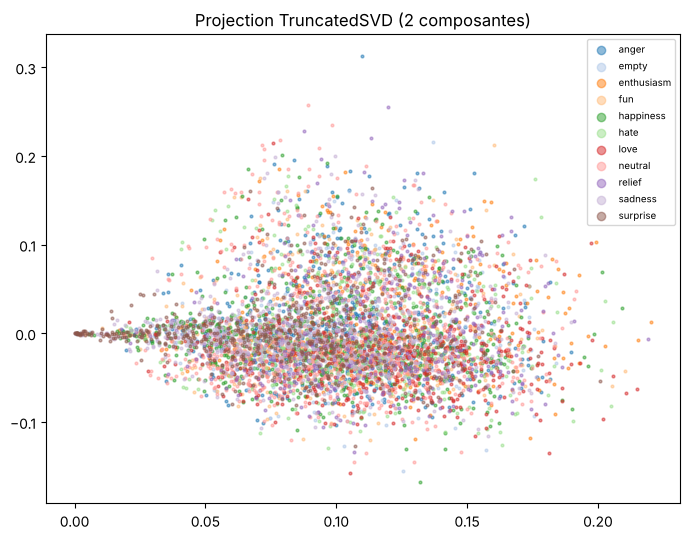

In [9]:
train, test = train_test_split(d, test_size=0.2, stratify=d.emotion, random_state=SEED)
R["n_train"], R["n_test"] = len(train), len(test)
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True)
X_train = tfidf.fit_transform(train.clean)        # appris sur l'entraînement seulement
X_test = tfidf.transform(test.clean)
R["tfidf_dim"] = X_train.shape[1]
R["tfidf_density_pct"] = round(X_train.nnz / (X_train.shape[0] * X_train.shape[1]) * 100, 4)

sample = train.sample(6000, random_state=SEED)
svd = TruncatedSVD(n_components=2, random_state=SEED)
Z = svd.fit_transform(tfidf.transform(sample.clean))
R["svd_var"] = [round(float(v), 4) for v in svd.explained_variance_ratio_]
labels = sorted(d.emotion.unique()); cmap = plt.get_cmap("tab20")
plt.figure(figsize=(7, 5.5))
for i, e in enumerate(labels):
    m = (sample.emotion == e).values
    plt.scatter(Z[m, 0], Z[m, 1], s=4, alpha=.5, label=e, color=cmap(i))
plt.legend(markerscale=3, fontsize=7); plt.title("Projection TruncatedSVD (2 composantes)")
save_fig("06_svd.png")

## 5. Data enrichment : nouvelles variables

In [10]:
for df_ in (train, test):
    df_["n_clean"] = df_.clean.str.split().str.len()
    df_["longueur"] = pd.cut(df_.n_clean, bins=[0, 10, 20, 40, 100], labels=["court", "moyen", "long", "tres_long"])
mn, mx = train.n_clean.min(), train.n_clean.max()    # bornes apprises sur l'entraînement
for df_ in (train, test):
    df_["n_clean_01"] = (df_.n_clean - mn) / (mx - mn)
R["longueur_counts"] = train.longueur.value_counts().to_dict()
R["n_clean_bounds"] = [int(mn), int(mx)]

d.to_csv(os.path.join(PROC, "dataset_clean.csv"), index=False)
train.to_csv(os.path.join(PROC, "train.csv"), index=False)
test.to_csv(os.path.join(PROC, "test.csv"), index=False)

## 6. Data transformation / enrichment : représentation en graphe
Nœud = un texte ; arête = au moins K mots-clés communs ; poids = nombre de mots communs.

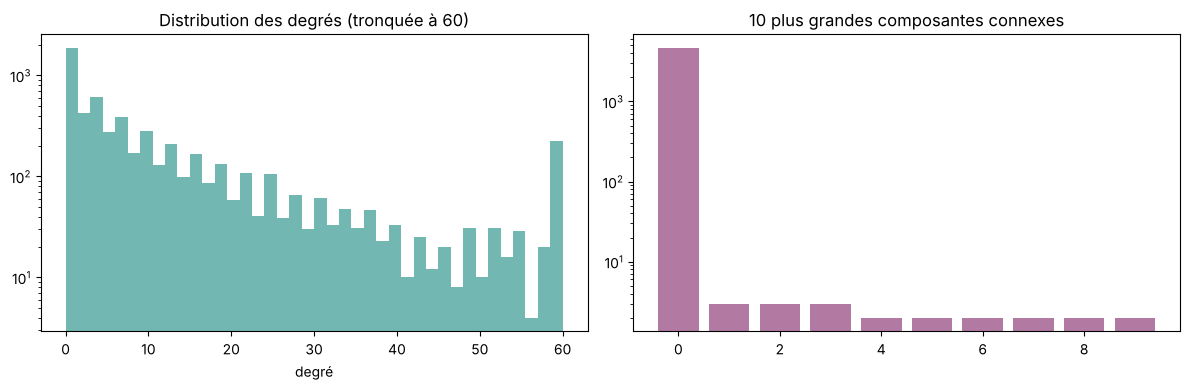

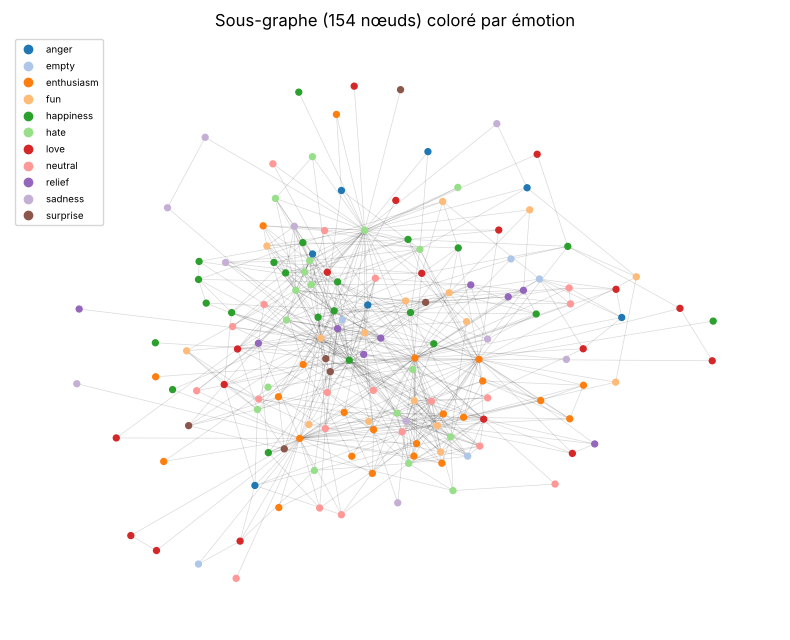

In [11]:
N = 6000
gs, _ = train_test_split(d, train_size=N, stratify=d.emotion, random_state=SEED)
gs = gs.reset_index(drop=True)
STOP = set(ENGLISH_STOP_WORDS) | {"feel", "feeling", "felt", "like", "im", "ive", "just", "really", "ll", "don", "didn"}
cv = CountVectorizer(binary=True, stop_words=list(STOP), min_df=3, max_df=0.05, token_pattern=r"[a-z']{3,}")
B = cv.fit_transform(gs.clean).astype(np.float32)
S = (B @ B.T).tocsr(); S.setdiag(0); S.eliminate_zeros()
R["graph_vocab"] = B.shape[1]; R["graph_pairs_any"] = int(S.nnz // 2)

R["K_table"] = []
for K in (2, 3, 4):
    Sk = S.copy(); Sk.data = np.where(Sk.data >= K, Sk.data, 0); Sk.eliminate_zeros()
    r, c = Sk.nonzero(); dg = np.diff(Sk.indptr)
    R["K_table"].append({"K": K, "aretes": int(Sk.nnz // 2), "isoles": int((dg == 0).sum()),
                         "deg_moyen": round(float(dg.mean()), 1),
                         "homophilie": round(float((gs.emotion.values[r] == gs.emotion.values[c]).mean()), 3)})

K = 2
Sg = S.copy(); Sg.data = np.where(Sg.data >= K, Sg.data, 0); Sg.eliminate_zeros()
G = nx.from_scipy_sparse_array(Sg)
for i, e in enumerate(gs.emotion): G.nodes[i]["emotion"] = e
deg = np.array([dg for _, dg in G.degree()])
comps = list(nx.connected_components(G)); giant = max(comps, key=len)
r, c = Sg.nonzero()
R["graph"] = {"K": K, "nodes": G.number_of_nodes(), "edges": G.number_of_edges(), "density": round(nx.density(G), 5),
              "deg_mean": round(float(deg.mean()), 2), "deg_max": int(deg.max()), "isolated": int((deg == 0).sum()),
              "components": len(comps), "giant": len(giant),
              "homophily": round(float((gs.emotion.values[r] == gs.emotion.values[c]).mean()), 3),
              "homophily_random": round(float(((gs.emotion.value_counts() / N) ** 2).sum()), 3)}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(deg.clip(max=60), bins=40, color="#72B7B2"); ax[0].set_yscale("log"); ax[0].set_xlabel("degré")
ax[0].set_title("Distribution des degrés (tronquée à 60)")
sizes = sorted([len(x) for x in comps], reverse=True)[:10]
ax[1].bar(range(len(sizes)), sizes, color="#B279A2"); ax[1].set_yscale("log"); ax[1].set_title("10 plus grandes composantes connexes")
save_fig("07_graphe_statistiques.png")

hubs = [int(h) for h in np.argsort(-deg)[:6]]
nodes = set(hubs)
for h in hubs: nodes |= set(list(G.neighbors(h))[:35])
H = G.subgraph(nodes); pos = nx.spring_layout(H, seed=SEED, k=0.25)
colors = {e: cmap(i) for i, e in enumerate(labels)}
fig, ax = plt.subplots(figsize=(8, 6.5))
nx.draw_networkx_edges(H, pos, alpha=.15, width=.5, ax=ax)
nx.draw_networkx_nodes(H, pos, node_size=18, node_color=[colors[H.nodes[n]["emotion"]] for n in H], ax=ax)
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=colors[e], label=e) for e in labels], fontsize=7, loc="upper left")
ax.set_title(f"Sous-graphe ({H.number_of_nodes()} nœuds) coloré par émotion"); ax.axis("off")
save_fig("08_sous_graphe.png")
R["subgraph_nodes"] = H.number_of_nodes()

gs.to_csv(os.path.join(PROC, "graph_nodes.csv"), index=False)
sp.save_npz(os.path.join(PROC, "graph_adj.npz"), Sg)

### Exemples avant / après nettoyage

In [12]:
pats = {"url_mention": r"http|www\.|@", "chiffres": r"\d", "majuscules_ponct": r"[A-Z].*[!?.]", "non_ascii": r"[^\x00-\x7f]"}
R["examples_clean"] = []
for k, p in pats.items():
    cand = d[d.text.str.contains(p) & d.text.str.len().between(35, 110) & (d.clean.str.split().str.len() >= 5)]
    row = cand.sample(1, random_state=7).iloc[0]
    R["examples_clean"].append({"type": k, "text": row.text, "clean": row.clean, "emotion": row.emotion})

In [13]:
json.dump(R, open(os.path.join(PROC, "resultats_phase1.json"), "w"), indent=1, ensure_ascii=False, default=str)
print("Phase 1 terminée :", R["n_after"], "textes conservés ;", R["graph"]["edges"], "arêtes dans le graphe.")

Phase 1 terminée : 79565 textes conservés ; 36471 arêtes dans le graphe.
